In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import zipfile
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
from google.colab import files

uploaded = files.upload()

# Find CSV files or extract an uploaded ZIP file
for filename in uploaded.keys():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as zip_ref:
            zip_ref.extractall("/content/anime_data")

csv_files = glob.glob("/content/*.csv")
csv_files += glob.glob(
    "/content/anime_data/**/*.csv",
    recursive=True
)

if not csv_files:
    raise FileNotFoundError("No CSV file found. Upload your Kaggle CSV or ZIP.")

# Load the first CSV file
df = pd.read_csv(csv_files[0])

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving Crunchyroll_Anime_Ratings_and_Reviews_Dataset.csv to Crunchyroll_Anime_Ratings_and_Reviews_Dataset (2).csv

Dataset loaded successfully!
Dataset shape: (500, 17)


,anime_id,anime_title,genre,type,episodes,release_year,studio,age_rating,average_rating,rating_count,review_count,popularity_rank,favorites_count,sub_available,dub_available,original_language,status
0,1,Anime Title 1,"Adventure, Action, Comedy",Movie,29,1999,Ufotable,G,8.45,17163,2002,1,99246,Yes,Yes,Japanese,Ongoing
1,2,Anime Title 2,"Romance, Slice of Life, Sci-Fi",Movie,58,2013,Toei Animation,G,9.00,84207,45803,2,444143,No,No,Japanese,Ongoing
2,3,Anime Title 3,Drama,TV,12,2007,Ufotable,PG-13,9.30,317026,17385,3,847335,Yes,No,Japanese,Ongoing
3,4,Anime Title 4,"Adventure, Slice of Life",OVA,81,2014,A-1 Pictures,PG,8.83,24525,43386,4,239968,No,Yes,Japanese,Ongoing
4,5,Anime Title 5,Sci-Fi,OVA,59,2015,A-1 Pictures,PG,7.72,110342,43970,5,280946,Yes,Yes,Japanese,Ongoing


In [7]:

print("\nDataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nMissing Values:")
display(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   anime_id           500 non-null    int64  
 1   anime_title        500 non-null    object 
 2   genre              500 non-null    object 
 3   type               500 non-null    object 
 4   episodes           500 non-null    int64  
 5   release_year       500 non-null    int64  
 6   studio             500 non-null    object 
 7   age_rating         500 non-null    object 
 8   average_rating     500 non-null    float64
 9   rating_count       500 non-null    int64  
 10  review_count       500 non-null    int64  
 11  popularity_rank    500 non-null    int64  
 12  favorites_count    500 non-null    int64  
 13  sub_available      500 non-null    object 
 14  dub_available      500 non-null    object 
 15  original_language  500 non-null    object 
 16  stat

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
anime_id,500.0,NaN,NaN,NaN,250.5,144.481833,1.0,125.75,250.5,375.25,500.0
anime_title,500,500,Anime Title 1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre,500,236,Drama,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,500,4,Special,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
episodes,500.0,NaN,NaN,NaN,51.626,28.918345,1.0,24.0,53.5,76.25,100.0
release_year,500.0,NaN,NaN,NaN,2010.224,8.666258,1995.0,2003.0,2010.0,2018.0,2025.0
studio,500,8,Ufotable,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_rating,500,4,R,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN
average_rating,500.0,NaN,NaN,NaN,8.12512,0.949309,6.51,7.36,8.105,8.95,9.8
rating_count,500.0,NaN,NaN,NaN,249313.628,144757.448813,1320.0,116990.25,250651.5,372466.25,498864.0



Missing Values:


,0
anime_id,0
anime_title,0
genre,0
type,0
episodes,0
release_year,0
studio,0
age_rating,0
average_rating,0
rating_count,0


In [8]:
# ============================================================
# 4. DATA CLEANING
# ============================================================

# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove completely empty columns
df = df.dropna(axis=1, how="all")

# Clean column names
df.columns = df.columns.str.strip()

print("\nAfter cleaning:")
print("Dataset shape:", df.shape)

print("\nMissing values after cleaning:")
display(df.isnull().sum())



After cleaning:
Dataset shape: (500, 17)

Missing values after cleaning:


,0
anime_id,0
anime_title,0
genre,0
type,0
episodes,0
release_year,0
studio,0
age_rating,0
average_rating,0
rating_count,0


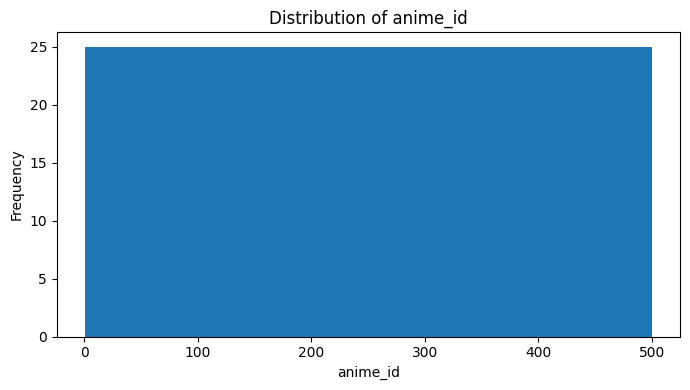

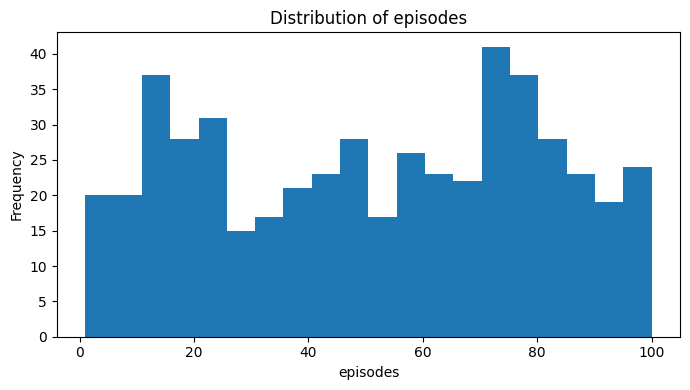

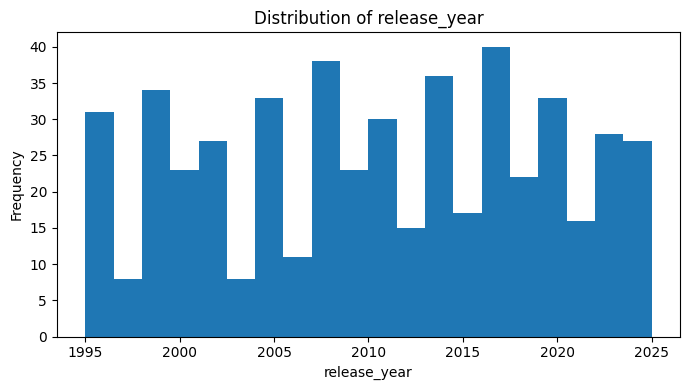

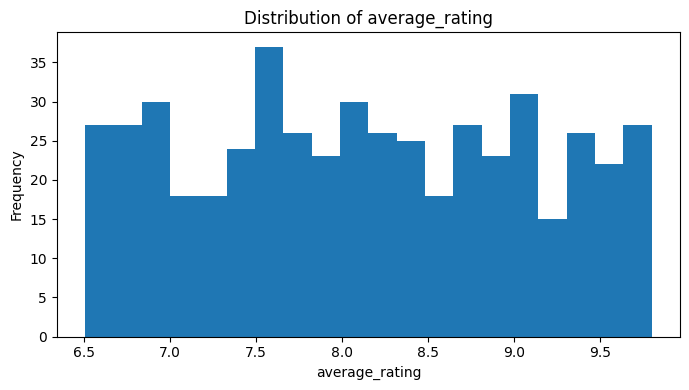

In [9]:
# ============================================================
# 5. EXPLORATORY DATA ANALYSIS
# ============================================================

# Identify numeric columns
numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

# Numerical distribution charts
for col in numeric_cols[:4]:
    plt.figure(figsize=(7, 4))
    plt.hist(df[col].dropna(), bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


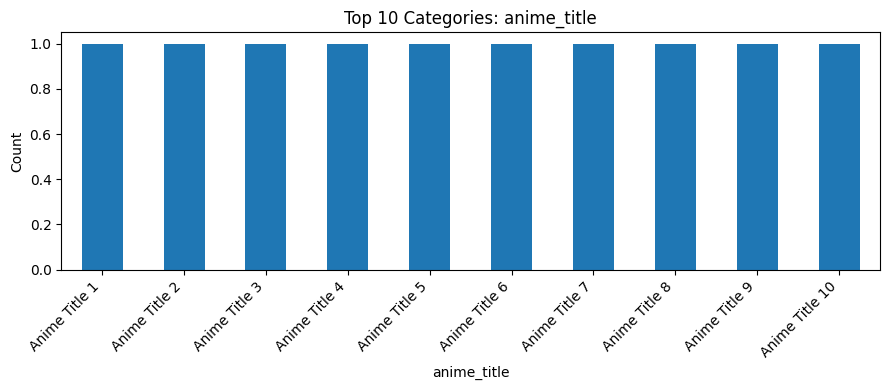

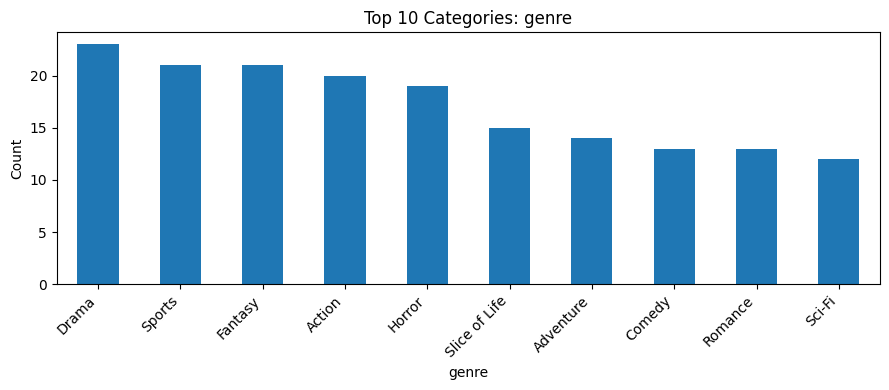

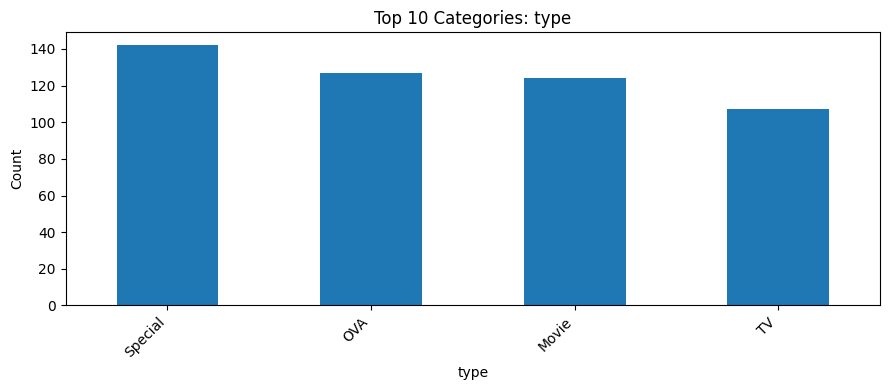

In [10]:
# ============================================================
# 6. CATEGORICAL DATA ANALYSIS
# ============================================================

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols[:3]:
    counts = df[col].value_counts().head(10)

    if len(counts) > 0:
        plt.figure(figsize=(9, 4))
        counts.plot(kind="bar")
        plt.title(f"Top 10 Categories: {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()


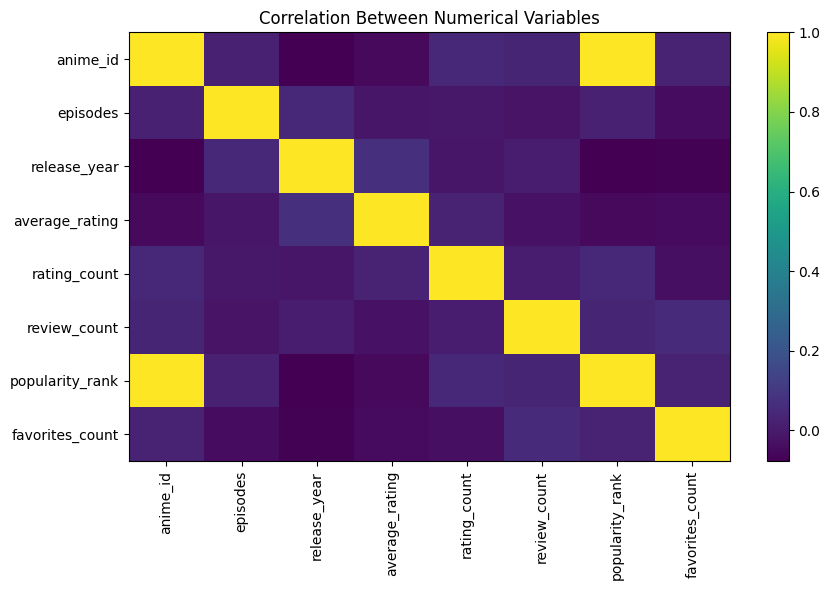


Correlation Matrix:


,anime_id,episodes,release_year,average_rating,rating_count,review_count,popularity_rank,favorites_count
anime_id,1.000000,0.021153,-0.077595,-0.048955,0.042927,0.035799,1.000000,0.025377
episodes,0.021153,1.000000,0.045962,-0.012003,-0.008910,-0.019185,0.021153,-0.042852
release_year,-0.077595,0.045962,1.000000,0.073542,-0.011054,0.003213,-0.077595,-0.070274
average_rating,-0.048955,-0.012003,0.073542,1.000000,0.024383,-0.023488,-0.048955,-0.045198
rating_count,0.042927,-0.008910,-0.011054,0.024383,1.000000,0.004453,0.042927,-0.033119
review_count,0.035799,-0.019185,0.003213,-0.023488,0.004453,1.000000,0.035799,0.056136
popularity_rank,1.000000,0.021153,-0.077595,-0.048955,0.042927,0.035799,1.000000,0.025377
favorites_count,0.025377,-0.042852,-0.070274,-0.045198,-0.033119,0.056136,0.025377,1.000000


In [11]:
# ============================================================
# 7. CORRELATION ANALYSIS
# ============================================================

if len(numeric_cols) >= 2:
    plt.figure(figsize=(9, 6))

    correlation = df[numeric_cols].corr()

    plt.imshow(correlation, aspect="auto")
    plt.colorbar()

    plt.xticks(
        range(len(numeric_cols)),
        numeric_cols,
        rotation=90
    )

    plt.yticks(
        range(len(numeric_cols)),
        numeric_cols
    )

    plt.title("Correlation Between Numerical Variables")
    plt.tight_layout()
    plt.show()

    print("\nCorrelation Matrix:")
    display(correlation)

In [12]:
# ============================================================
# 8. FEATURE ENGINEERING
# ============================================================

df_analysis = df.copy()

# Create genre count if a genre column exists
genre_col = next(
    (c for c in df_analysis.columns
     if "genre" in c.lower()),
    None
)

if genre_col is not None:
    df_analysis["Genre_Count"] = (
        df_analysis[genre_col]
        .fillna("")
        .astype(str)
        .apply(
            lambda x: len([
                g for g in x.split(",") if g.strip()
            ])
        )
    )

# Create text length features where useful
for col in df_analysis.select_dtypes(
    include="object"
).columns:
    if any(word in col.lower() for word in
           ["review", "description", "synopsis"]):
        df_analysis[col + "_Length"] = (
            df_analysis[col]
            .fillna("")
            .astype(str)
            .str.len()
        )

print("Feature engineering completed!")

display(df_analysis.head())

Feature engineering completed!


,anime_id,anime_title,genre,type,episodes,release_year,studio,age_rating,average_rating,rating_count,review_count,popularity_rank,favorites_count,sub_available,dub_available,original_language,status,Genre_Count
0,1,Anime Title 1,"Adventure, Action, Comedy",Movie,29,1999,Ufotable,G,8.45,17163,2002,1,99246,Yes,Yes,Japanese,Ongoing,3
1,2,Anime Title 2,"Romance, Slice of Life, Sci-Fi",Movie,58,2013,Toei Animation,G,9.00,84207,45803,2,444143,No,No,Japanese,Ongoing,3
2,3,Anime Title 3,Drama,TV,12,2007,Ufotable,PG-13,9.30,317026,17385,3,847335,Yes,No,Japanese,Ongoing,1
3,4,Anime Title 4,"Adventure, Slice of Life",OVA,81,2014,A-1 Pictures,PG,8.83,24525,43386,4,239968,No,Yes,Japanese,Ongoing,2
4,5,Anime Title 5,Sci-Fi,OVA,59,2015,A-1 Pictures,PG,7.72,110342,43970,5,280946,Yes,Yes,Japanese,Ongoing,1



Machine Learning Target: average_rating

MODEL EVALUATION
------------------------
MAE: 0.7981
RMSE: 0.9654
R2 Score: -0.032


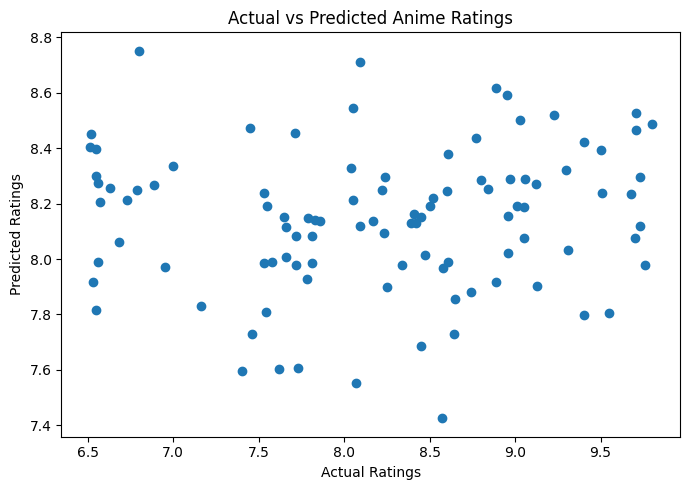

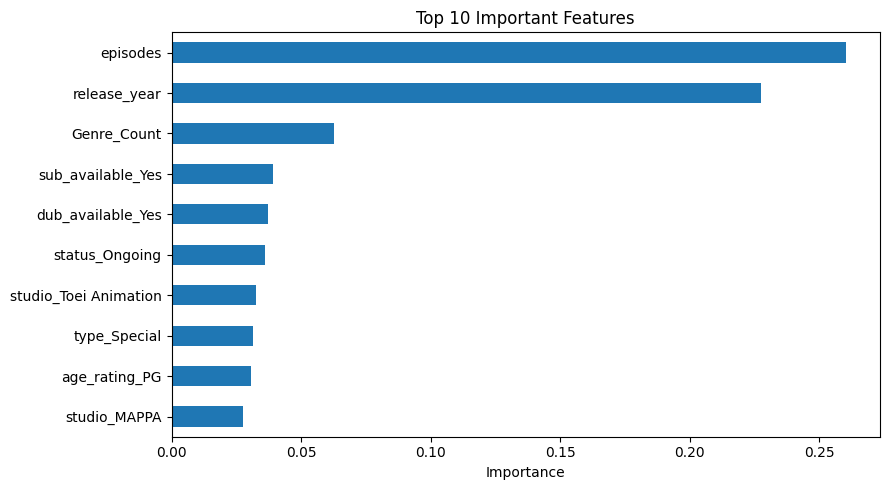


Top Important Features:


,0
episodes,0.260460
release_year,0.227465
Genre_Count,0.062875
sub_available_Yes,0.039174
dub_available_Yes,0.037075
status_Ongoing,0.036191
studio_Toei Animation,0.032408
type_Special,0.031564
age_rating_PG,0.030750
studio_MAPPA,0.027504


In [13]:
# ============================================================
# 9. MACHINE LEARNING
# ============================================================

# Automatically identify a possible rating or score column
target_candidates = [
    c for c in df_analysis.columns
    if any(word in c.lower() for word in
           ["rating", "score"])
]

target_col = None

for col in target_candidates:
    converted = pd.to_numeric(
        df_analysis[col],
        errors="coerce"
    )

    if converted.notna().sum() >= 20:
        target_col = col
        df_analysis[col] = converted
        break

if target_col is None:
    print(
        "\nNo suitable numeric rating/score target was found."
    )
    print("Available columns:", df_analysis.columns.tolist())
    print(
        "Choose a suitable numeric target column manually "
        "before running the machine learning section."
    )

else:
    print("\nMachine Learning Target:", target_col)

    # Remove rows with missing target
    ml_data = df_analysis.dropna(
        subset=[target_col]
    ).copy()

    # Keep useful numerical and categorical features
    X = ml_data.drop(columns=[target_col])
    y = ml_data[target_col]

    # Remove columns that are almost entirely unique,
    # such as anime titles and long descriptions
    X = X.drop(
        columns=[
            c for c in X.columns
            if X[c].nunique(dropna=True) > 0.8 * len(X)
        ],
        errors="ignore"
    )

    # Keep only manageable categorical columns
    cat_cols = X.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    X = X.drop(
        columns=[
            c for c in cat_cols
            if X[c].nunique(dropna=True) > 30
        ],
        errors="ignore"
    )

    # Fill missing values
    for col in X.select_dtypes(
        include=np.number
    ).columns:
        X[col] = X[col].fillna(X[col].median())

    for col in X.select_dtypes(
        include=["object", "category"]
    ).columns:
        X[col] = X[col].fillna("Unknown")

    # One-hot encode categorical variables
    X = pd.get_dummies(X, drop_first=True)

    # Keep numerical features only
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(0)

    if len(X) >= 20 and X.shape[1] > 0:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=0.2,
            random_state=42
        )

        # Random Forest Regression
        model = RandomForestRegressor(
            n_estimators=100,
            random_state=42
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        # Model evaluation
        mae = mean_absolute_error(y_test, predictions)
        rmse = np.sqrt(
            mean_squared_error(y_test, predictions)
        )
        r2 = r2_score(y_test, predictions)

        print("\nMODEL EVALUATION")
        print("------------------------")
        print("MAE:", round(mae, 4))
        print("RMSE:", round(rmse, 4))
        print("R2 Score:", round(r2, 4))

        # Actual vs Predicted
        plt.figure(figsize=(7, 5))
        plt.scatter(y_test, predictions)
        plt.xlabel("Actual Ratings")
        plt.ylabel("Predicted Ratings")
        plt.title("Actual vs Predicted Anime Ratings")
        plt.tight_layout()
        plt.show()

        # Feature Importance
        importance = pd.Series(
            model.feature_importances_,
            index=X.columns
        ).sort_values(ascending=False).head(10)

        plt.figure(figsize=(9, 5))
        importance.sort_values().plot(kind="barh")
        plt.title("Top 10 Important Features")
        plt.xlabel("Importance")
        plt.tight_layout()
        plt.show()

        print("\nTop Important Features:")
        display(importance)

    else:
        print("Not enough usable features or records for ML.")

In [14]:
# ============================================================
# 10. BUSINESS RECOMMENDATIONS
# ============================================================

print("""
BUSINESS RECOMMENDATIONS

1. Streaming platforms should study anime ratings
   before investing in new content.

2. Genre analysis can help identify audience preferences.

3. Popularity patterns can help improve recommendation
   systems.

4. Machine learning can help estimate potential anime ratings.

5. Platforms can use data-driven insights to improve
   content selection and audience engagement.
""")




BUSINESS RECOMMENDATIONS

1. Streaming platforms should study anime ratings
   before investing in new content.

2. Genre analysis can help identify audience preferences.

3. Popularity patterns can help improve recommendation
   systems.

4. Machine learning can help estimate potential anime ratings.

5. Platforms can use data-driven insights to improve
   content selection and audience engagement.



In [15]:

# ============================================================
# 11. CONCLUSION
# ============================================================

print("""
CONCLUSION

This project explored anime ratings, popularity,
genres and other available features.

Data cleaning and exploratory data analysis helped
understand the dataset.

Feature engineering prepared the data for analysis
and machine learning.

The results can help streaming platforms make
better content and recommendation decisions.
""")



CONCLUSION

This project explored anime ratings, popularity,
genres and other available features.

Data cleaning and exploratory data analysis helped
understand the dataset.

Feature engineering prepared the data for analysis
and machine learning.

The results can help streaming platforms make
better content and recommendation decisions.



In [16]:
# ============================================================
# 12. SAVE OUTPUT FILES
# ============================================================

df_analysis.to_csv(
    "/content/cleaned_anime_dataset.csv",
    index=False
)

print("\nProject completed!")
print("Cleaned dataset saved successfully.")




Project completed!
Cleaned dataset saved successfully.


In [17]:
files.download("/content/cleaned_anime_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>